In [1]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

import ipywidgets

from tf_ofcs.components import *
from tf_ofcs.datatypes import ElectricalSignal, OpticalSignal
from tf_ofcs.utils import dbm_to_w, from_db, symbol_mapping_to_gray
from tf_ofcs.plot import *

from typing import Optional
from collections.abc import Sequence

2024-11-17 19:08:17.026498: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-11-17 19:08:17.185381: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-17 19:08:17.185409: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-17 19:08:17.196327: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-17 19:08:17.227567: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-11-17 19:08:17.227820: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = False

class LowPassFilter(BandPassFilter):
    def __init__(self, max_frequency: float | Sequence[float] | tf.Tensor, name: Optional[str] = None) -> None:
        super().__init__(min_frequency=0.0, max_frequency=max_frequency, name=name)

qam4_mapping = tf.constant([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = tf.constant(symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  1/3], [-1.0, -1/3], [-1.0, -1.0],
    [-1/3, -1.0], [-1/3, -1/3], [-1/3,  1/3], [-1/3,  1.0],
    [ 1/3,  1.0], [ 1/3,  1/3], [ 1/3, -1/3], [ 1/3, -1.0],
    [ 1.0, -1.0], [ 1.0, -1/3], [ 1.0,  1/3], [ 1.0,  1.0]
]))

bits_per_symbol, symbol_mapping = 2, qam4_mapping


class DWDMSystem(Composition):
    n_channels: int
    frequencies: Sequence[float]
    channel_width: float
    rng: tf.random.Generator
    
    def __init__(self, frequencies: Sequence[float], channel_width: float, name: Optional[str] = None) -> None:
        self.frequencies = frequencies
        self.n_channels = len(frequencies)
        self.channel_width = channel_width

        self.rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
        
        self.channel = Composition([
            OpticalAWGN(relative_db=-40.0, rng=self.rng),
            OpticalFiber(
                attenuation=0.22,
                length=40.0,
                chromatic_dispersion=17.0,
                eff_non_linear_coeff=1.76,
                central_frequency=193.414e12,
                step_count=1000
            )
        ])

        self.input_laser = Laser(
            power=1e-3,
            frequency=self.frequencies,
            parameter_dims=self.n_channels
        )

        self.local_oscillator = Laser(
            power=1e-3,
            frequency=self.frequencies,
            parameter_dims=self.n_channels,
            name="local_oscillator"
        )

        self.photodiode = Composition([
            Photodiode(),
            Quantizer(step=1e-4),
            LowPassFilter(max_frequency=10e9)
        ])

        self.iq_receiver = IQReceiver(
            photodiode=self.photodiode,
            local_oscillator=self.local_oscillator,
            name="receiver1"
        )

        self.transmitter = Composition([
            Composition([
                IQEncoder(
                    sampling_rate=100e9,
                    data_rate=10e9,
                    symbol_encoder=IQSymbolEncoder(
                        bits_per_symbol=bits_per_symbol,
                        mapping=symbol_mapping,
                        adjust_for_mzm=True
                    )
                ),
                MapComponents(LowPassFilter(max_frequency=10e9))
            ], name="encoder"),
            MapComponents(RedistributeDimensions((1, self.n_channels))),
            IQModulator(carrier_source=self.input_laser, name="modulator"),
            RedistributeDimensions((self.n_channels, 1)),
            OpticalMultiplexer(self.n_channels)
        ])

        self.receiver = Composition([
            OpticalDemultiplexer(frequencies, channel_width),
            IQReceiver(
                photodiode=self.photodiode,
                local_oscillator=Composition([self.local_oscillator, RedistributeDimensions((self.n_channels, 1))]),
                name="receiver"
            ),
            MapComponents(ElectricalGain(gain=1.0)),
            IQDecoder(
                data_rate=10e9,
                symbol_decoder=IQSymbolDecoder(
                    bits_per_symbol=bits_per_symbol,
                    mapping=symbol_mapping
                )
            )
        ])

        super().__init__([
            self.transmitter,
            self.channel,
            self.receiver
        ], name=name)

system = DWDMSystem(frequencies=[-40e9, -30e9, -20e9, -10e9, 0.0, 10e9, 20e9, 30e9, 40e9], channel_width=5e9)

channel_loss_estimator = ChannelLossEstimator(
    laser=system.input_laser,
    photodiode=Composition([
        system.iq_receiver,
        Lambda(
            lambda x: ElectricalSignal(
                timing=x[0].timing,
                samples=(tf.abs(x[0].samples) + tf.abs(x[1].samples)) / (2 * 0.5 ** 0.5)
            )
        )
    ]),
    channel=system.channel,
    sampling_rate=1e9
)

In [3]:
input_signal = system.rng.uniform((len(system.frequencies), 512), 0, 2, dtype=tf.int32)

data_rate = 5e9
sampling_rate = 100e9
central_frequency = 193.414e12 # Hz

input_power = dbm_to_w(7.0) # Watts

bits_per_symbol = 4
symbol_mapping = qam16_mapping
channel_osnr = 40.0
cutoff_frequency = 5.0 * data_rate

symbol_scale = 1.0

def plot(eff_non_linear_coeff: float, chromatic_dispersion: float, xt_attenuation: float) -> go.Figure:
    global symbol_scale

    system_params = dict(
        laser__power=tf.constant(input_power),
        optical_fiber__attenuation=tf.constant(0.22),
        optical_fiber__step_count=tf.constant(10),
        optical_fiber__length=tf.constant(20.0),
        optical_fiber__eff_non_linear_coeff=tf.constant(eff_non_linear_coeff),
        optical_fiber__chromatic_dispersion=tf.constant(chromatic_dispersion),
        iq_encoder__data_rate=tf.constant(data_rate),
        iq_encoder__sampling_rate=tf.constant(sampling_rate),
        iq_decoder__data_rate=tf.constant(data_rate),
        iq_symbol_encoder__bits_per_symbol=tf.constant(bits_per_symbol),
        iq_symbol_decoder__bits_per_symbol=tf.constant(bits_per_symbol),
        iq_symbol_encoder__mapping=symbol_mapping,
        iq_symbol_decoder__mapping=symbol_mapping,
        optical_awgn__relative_db=tf.constant(-channel_osnr),
        low_pass_filter__max_frequency=tf.constant(cutoff_frequency),
        quantizer__step=tf.constant(1e-9),
        photodiode__sensitivity=dbm_to_w(-20.0),
        photodiode__maximum_power=dbm_to_w(3.0),
        optical_demultiplexer__crosstalk_attenuation=tf.constant(xt_attenuation)
    )

    system.rng.reset_from_seed(1234)
    
    estimated_channel_loss = channel_loss_estimator(
        1000e-9,
        parameter_dims=len(system.frequencies),
        **system_params
    )[0]
    
    symbol_scale = input_power / estimated_channel_loss
    system_params["electrical_gain__gain"] = 1.0 / symbol_scale
    
    system.trace(input_signal, **system_params)

    fig = make_subplots(
        rows=3,
        cols=2,
        subplot_titles=(
            "Input sequence", "Decoded sequence",
            "Encoded signal", "Output signal",
            "Signal after fiber", "Received signal"
        ),
        vertical_spacing = 0.05
    )

    plot_bitseq(input_signal, fig, 2, row=1, col=1)
    plot_bitseq(system.output, fig, (2, 0), row=1, col=2)
    plot_envelope(system.find_child("encoder").output, fig, row=2, col=1)
    plot_power(system.find_child("modulator").output, fig, (0, 2), row=2, col=2)
    plot_power(system.find_child("optical_fiber").output, fig, row=3, col=1)
    
    plot_power(system.find_child("optical_demultiplexer").output, fig, (2, 0), row=3, col=2)

    fig.update_layout(
        autosize=True,
        height=1000,
        margin=dict(t=30, b=30)
    )

    return fig

ipywidgets.interact(plot, eff_non_linear_coeff=(0.0, 10000, 0.01), chromatic_dispersion=(-500.0, 500.0, 1.0), xt_attenuation=(0.0, 100.0, 0.1))

interactive(children=(FloatSlider(value=5000.0, description='eff_non_linear_coeff', max=10000.0, step=0.01), F…

<function __main__.plot(eff_non_linear_coeff: float, chromatic_dispersion: float, xt_attenuation: float) -> plotly.graph_objs._figure.Figure>

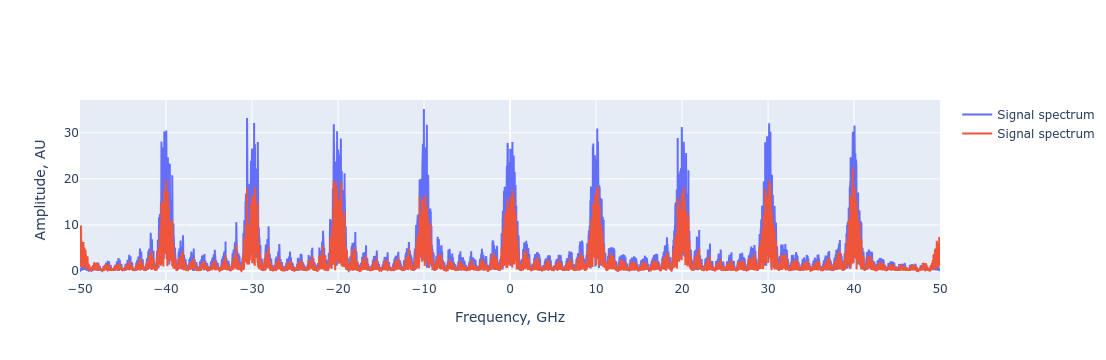

In [10]:
fig = plot_spectrum(system.find_child("optical_multiplexer").output, None)
plot_spectrum(system.find_child("optical_fiber").output, fig)

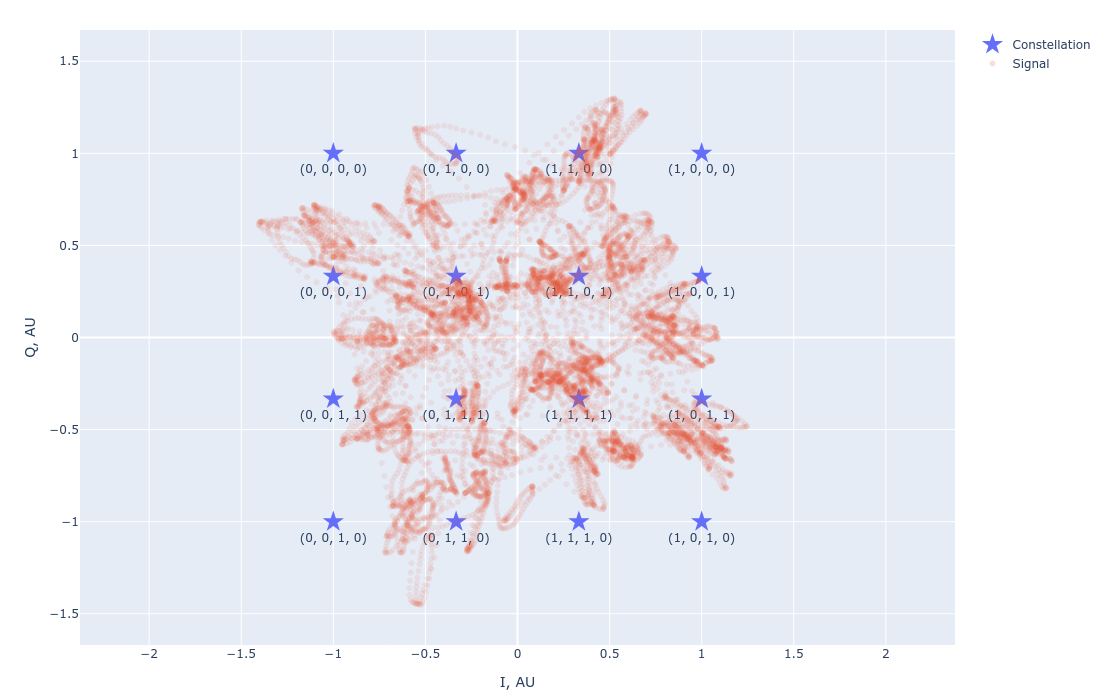

In [5]:
annotate_constellation = True
annotations = []

if annotate_constellation:
    for i, symbol in enumerate(symbol_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        annotations.append(f"({bit_string})")

fig = plot_iq_constellation(
    tf.expand_dims(symbol_mapping, 0),
    label="Constellation",
    mode="markers+text",
    text=annotations,
    textposition="bottom center",
    marker=dict(size=16, symbol="star")
)

fig = plot_iq_constellation(
    system.find_child("receiver").output,
    fig,
    (2, 0),
    iq_units=(1 / symbol_scale[2], "AU"),
    label="Signal",
    marker=dict(size=6, opacity=0.1),
)

fig.update_yaxes(scaleanchor='x', range=[-1.5, 1.5])
fig.update_xaxes(range=[-1.5, 1.5])
fig.update_layout(width=800, height=700, margin=dict(t=30, b=30))
fig.show()

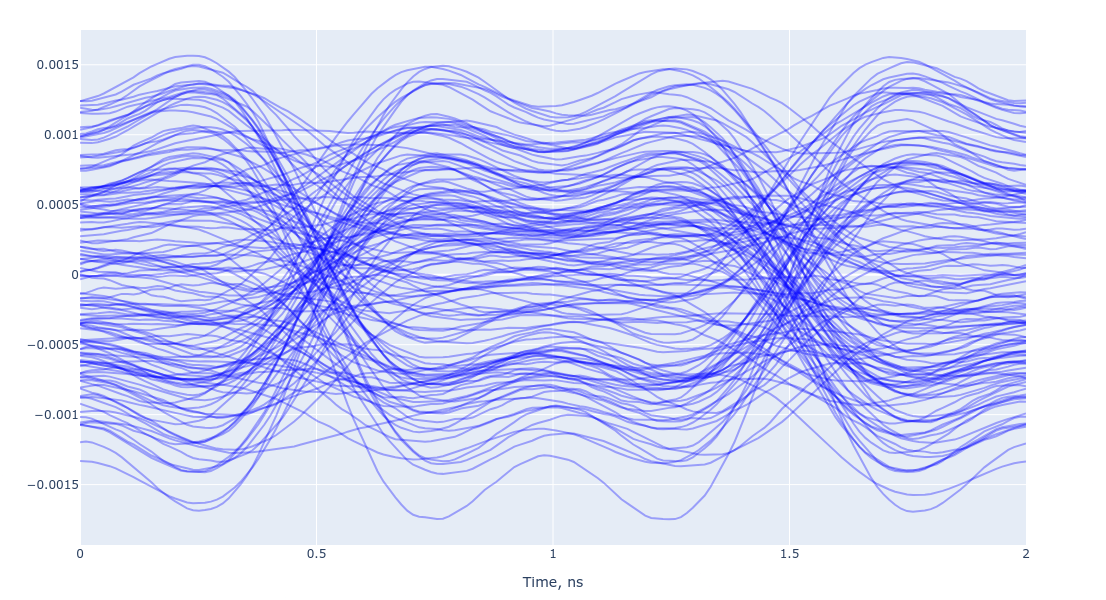

In [6]:
fig = go.Figure(layout=go.Layout(xaxis={"title": "Time, ns"}, showlegend=False))
for signal in system.find_child("receiver").output:
    plot_eye_diagram(signal, data_rate / bits_per_symbol, fig, (2, 0), line={"color": "rgba(0, 0, 255, 0.333)"})
fig.update_layout(autosize=True, height=600, margin=dict(t=30, b=30))
fig.show()

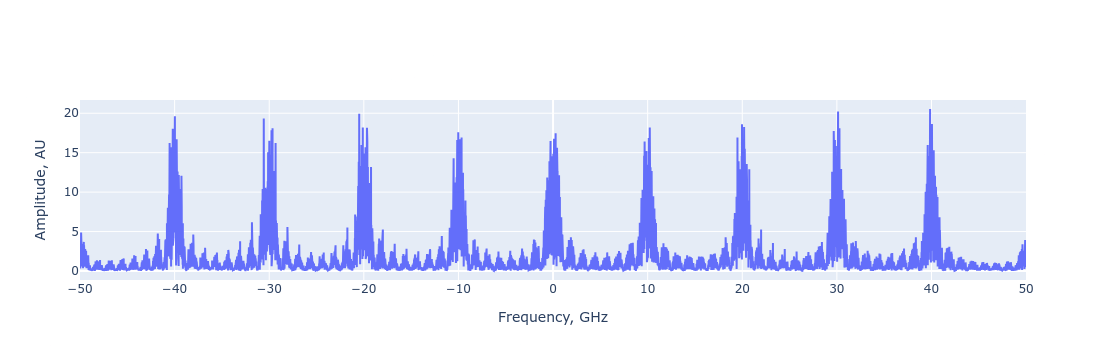

In [7]:
plot_spectrum(system.find_child("optical_fiber").output, None)